# Artificial Neural Network

In [1]:
class MP_OR:
    def __init__(self):
        self.theta=1
    def predict(self,x1,x2):
        g=x1+x2
        if g>=self.theta:
            return 1
        else:
            return 0
           

In [2]:
orfun=MP_OR()
print(orfun.predict(1,1))

1


In [3]:
orfun=MP_OR()
print(orfun.predict(0,0))

0


In [4]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
#import cv2
import matplotlib.pyplot as plt

In [5]:
fashion=keras.datasets.fashion_mnist
(x_train,y_train),(x_test,y_test)=fashion.load_data()

In [6]:
x_train.shape

(60000, 28, 28)

In [7]:
y_train.shape

(60000,)

In [8]:
x_test.shape

(10000, 28, 28)

In [9]:
y_test.shape

(10000,)

In [10]:
x_train,x_val=x_train[:10000]/255.0,x_train[10000:]/255.0
y_train,y_val=y_train[:10000],y_train[10000:]

In [11]:
y_train[3]

np.uint8(3)

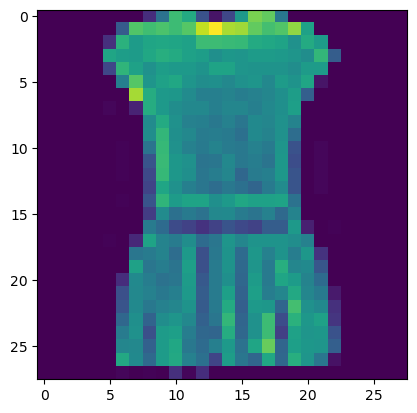

In [12]:
plt.imshow(x_train[3])

In [13]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat","Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [14]:
class_names[y_train[3]]

'Dress'

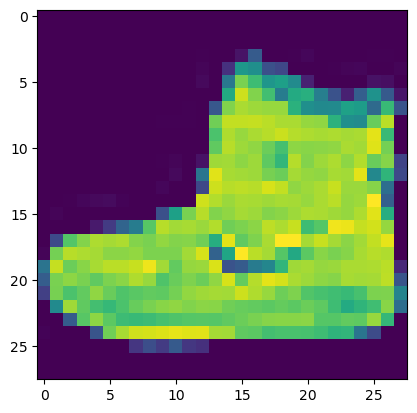

In [15]:
plt.imshow(x_train[0])

Dress


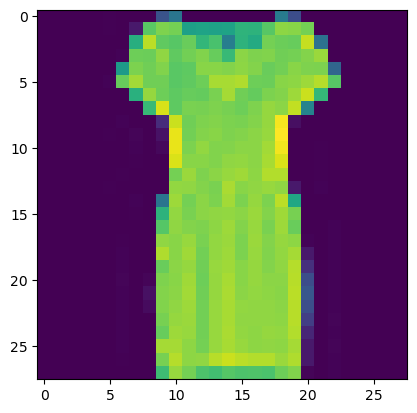

In [16]:
print(class_names[y_train[20]])
plt.imshow(x_train[20])

## Building Block of a neural network
First creates a Sequential model. This is the simplest kind of Keras model, for neural networks that are just composed of a single stack of layers, connecte sequentially. This is called the sequential API.

In [17]:
model=keras.models.Sequential()

Input data is an image of 2 dimensional. Neural network will take one dimensional input. Next, we required a Flatten layer whose role is simply to convert each input image into a 1D array.

In [18]:
model.add(keras.layers.Flatten(input_shape=[28,28]))

C:\Users\sarna\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## Add first hidden layer
Next we add a Dense hidden layer with 300 neurons. It will use the ReLU activation function. Each Dense layer manages its own weight matrix, containing all th connection weights between the neurons and their inputs.

In [19]:
model.add(keras.layers.Dense(300, activation="relu"))

## Add second hidden layer
Next we add another Dense hidden layer with 300 neurons. It will use the ReLU activation function. Each Dense layer manages its own weight matrix, containing all the connection weights between the neurons and their inputs.

In [20]:
model.add(keras.layers.Dense(100, activation="relu"))

## Add output layer
Number of class in the dataset is 10. therefore number of neurons at output layer is 10.

In [21]:
model.add(keras.layers.Dense(10,activation='softmax'))

## Model Summary
The model’s summary() method displays all the model’s layers13, including each layer’s name (which is automatically generated unless you set it when creating the layer), it output shape (None means the batch size can be anything), and its number of parameter . The summary ends with the total number of parameters, including trainable nd non-trainable parameters. Here we only have trainable parameters

In [22]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 300)                 │         235,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 100)                 │          30,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
model.layers

[<Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dense name=dense_1, built=True>,
 <Dense name=dense_2, built=True>]

In [24]:
model.layers[0]

<Flatten name=flatten, built=True>

In [25]:
model.layers[1].name

'dense'

In [26]:
weights,bias=model.layers[1].get_weights()

In [27]:
weights.shape

(784, 300)

In [28]:
bias.shape

(300,)

In [29]:
weights,bias=model.layers[2].get_weights()

In [30]:
bias

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
      dtype=float32)

## Compiling the Model
After a model is created, you must call its compile() method to specify the loss function and the optimizer to use. Optionally, you can also specify a list of extra metrics to compute during training and evaluation.

In [31]:
 model.compile(loss="sparse_categorical_crossentropy",optimizer="sgd",metrics=["accuracy"])

## Training and Evaluating the Model
Now the model is ready to be trained. For this we simply need to call its fit() method. We pass it the input features (X_train) and the target classes (y_train), as well as the number of epochs to train

In [32]:
history = model.fit(x_train, y_train, epochs=30,validation_data=(x_val, y_val))

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.6404 - loss: 1.2136 - val_accuracy: 0.7092 - val_loss: 0.8312
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7567 - loss: 0.7284 - val_accuracy: 0.7742 - val_loss: 0.6776
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7868 - loss: 0.6224 - val_accuracy: 0.7925 - val_loss: 0.5995
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8073 - loss: 0.5706 - val_accuracy: 0.7895 - val_loss: 0.5969
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8191 - loss: 0.5309 - val_accuracy: 0.8015 - val_loss: 0.5642
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8234 - loss: 0.5095 - val_accuracy: 0.8226 - val_loss: 0.5168
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8313 - loss: 0.4886 - val_accuracy: 0.8028 - val_loss: 0.5527
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8393 - loss: 0.4717 - val_accuracy: 0

The fit() method returns a History object containing the training parameters (his tory.params), the list of epochs it went through (history.epoch), and most importantly a dictionary (history.history) containing the loss and extra metrics it measured at the end of each epoch on the training set and on the validation set (if any)

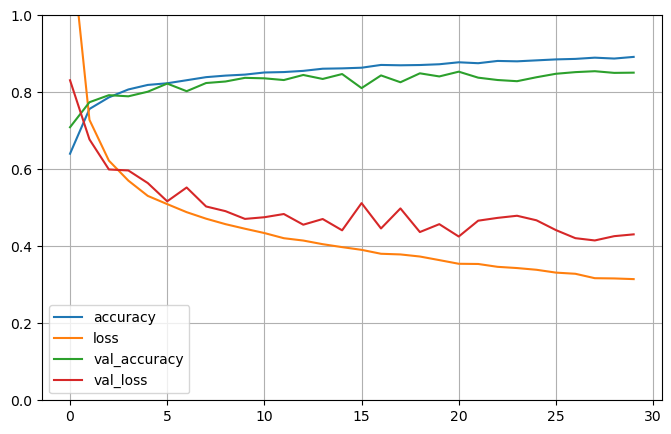

In [33]:
pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1) # set the vertical range to [0-1]
plt.show()

Once you are satisfied with your model’s validation accuracy, you should evaluate it on the test set to estimate the generalization error before you deploy the model to production. You can easily do this using the evaluate() method

In [34]:
model.evaluate(x_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8120 - loss: 86.2459   


[86.24591827392578, 0.8119999766349792]

## Using the Model to Make Predictions
Next, we can use the model’s predict() method to make predictions on new instances. Since we don’t have actual new instances, we will just use the first 3 instances of the test set:

In [35]:
X_new = x_test[:3]
y_proba = model.predict(X_new)
y_proba.round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step


array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

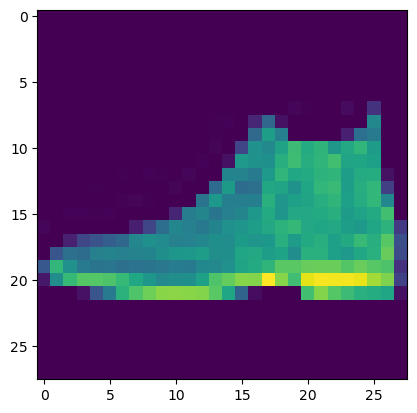

In [36]:

plt.imshow(x_test[0])

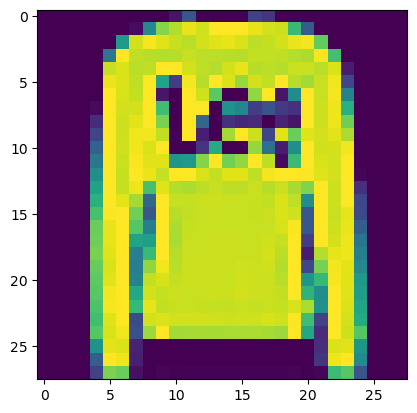

In [37]:

plt.imshow(x_test[1])

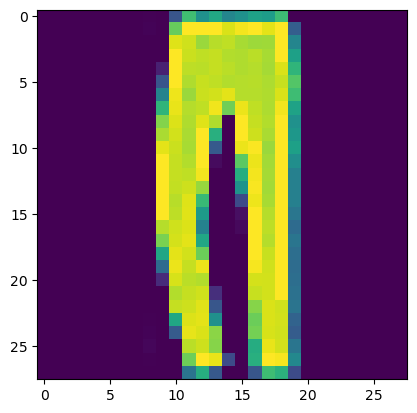

In [38]:

plt.imshow(x_test[2])

## Regression MLPs
MLPs can be used for regression tasks. If you want to predict a single value (e.g., the price of a house given many of its features), then you just need a single output neuron: its output is the predicted value. For multivariate regression (i.e., to predict multiple values at once), you need one output neuron per output dimension. For example, to locate the center of an object on an image, you need to predict 2D coordinates, so you need two output neurons. If you also want to place a bounding box around the object, then you need two more numbers: the width and the height of the object. So you end up with 4 output neurons.

In [39]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [40]:
housing = fetch_california_housing()


In [41]:
X_train_full, X_test, y_train_full, y_test = train_test_split(housing.data, housing.target)
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full)

In [42]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)


In [43]:
X_train.shape[1:]

(8,)

In [44]:
model = keras.models.Sequential([
keras.layers.Dense(30, activation="sigmoid", input_shape=X_train_scaled.shape[1:]),
keras.layers.Dense(1)
])

C:\Users\sarna\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [45]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 30)                  │             270 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │              31 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 301 (1.18 KB)

 Trainable params: 301 (1.18 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
model.compile(loss="mean_squared_error",optimizer="sgd")

In [47]:
history = model.fit(X_train_scaled,y_train, epochs=50,validation_data=(X_valid_scaled,y_valid))

Epoch 1/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.7621 - val_loss: 0.6273
Epoch 2/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5778 - val_loss: 0.5778
Epoch 3/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5442 - val_loss: 0.5510
Epoch 4/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5226 - val_loss: 0.5326
Epoch 5/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5063 - val_loss: 0.5193
Epoch 6/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4941 - val_loss: 0.5145
Epoch 7/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4846 - val_loss: 0.5040
Epoch 8/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4774 - val_loss: 0.4993
Epoch 9/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4733 - val_loss: 0.4958
Epoch 10/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4691 - val_loss: 0.4935
Epoch 11/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4658 - val_loss: 0.4916
Epoch 12/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

In [48]:
mse_test = model.evaluate(X_test_scaled, y_test)

162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 900us/step - loss: 0.3947


In [49]:
X_new = X_test_scaled[:3] # pretend these are new instances

In [50]:
y_pred = model.predict(X_new)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


In [51]:
y_pred

array([[2.515698 ],
       [1.3369036],
       [3.1823633]], dtype=float32)